In [1]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


In [2]:

np.random.seed(42)

n = 300

df = pd.DataFrame({
    "Customer_ID": range(1, n + 1),
    "Age": np.random.randint(18, 50, n),
    "Spending": np.random.randint(1000, 20000, n),
    "Visits": np.random.randint(1, 30, n),
    "Engagement": np.random.randint(1, 100, n),
    "Service_Interest": np.random.choice(
        ["Python", "Data Science", "AI/ML", "Web Development"],
        n
    ),
    "Service_Usage": np.random.randint(1, 15, n)
})

df.head()


,Customer_ID,Age,Spending,Visits,Engagement,Service_Interest,Service_Usage
0,1,24,8392,17,88,AI/ML,6
1,2,37,14949,4,79,Python,14
2,3,46,19091,12,30,Data Science,9
3,4,32,6791,29,51,Web Development,2
4,5,28,5931,9,81,Data Science,5


In [3]:

print(df.shape)

print(df.info())

print(df.describe())

print(df.isnull().sum())


(300, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Customer_ID       300 non-null    int64 
 1   Age               300 non-null    int64 
 2   Spending          300 non-null    int64 
 3   Visits            300 non-null    int64 
 4   Engagement        300 non-null    int64 
 5   Service_Interest  300 non-null    object
 6   Service_Usage     300 non-null    int64 
dtypes: int64(6), object(1)
memory usage: 16.5+ KB
None
       Customer_ID         Age      Spending      Visits  Engagement  \
count   300.000000  300.000000    300.000000  300.000000  300.000000   
mean    150.500000   33.936667  10308.630000   15.140000   47.636667   
std      86.746758    9.599296   5415.280019    8.537566   29.230682   
min       1.000000   18.000000   1190.000000    1.000000    1.000000   
25%      75.750000   25.000000   5735.750000    7.000000 

In [4]:

# Check duplicate rows
print(df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check missing values
print(df.isnull().sum())

# Fill missing numerical values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Spending"] = df["Spending"].fillna(df["Spending"].median())
df["Visits"] = df["Visits"].fillna(df["Visits"].median())
df["Engagement"] = df["Engagement"].fillna(df["Engagement"].median())
df["Service_Usage"] = df["Service_Usage"].fillna(df["Service_Usage"].median())


0
Customer_ID         0
Age                 0
Spending            0
Visits              0
Engagement          0
Service_Interest    0
Service_Usage       0
dtype: int64


In [5]:

print(df.groupby("Service_Interest")["Customer_ID"].count())


Service_Interest
AI/ML              85
Data Science       71
Python             73
Web Development    71
Name: Customer_ID, dtype: int64


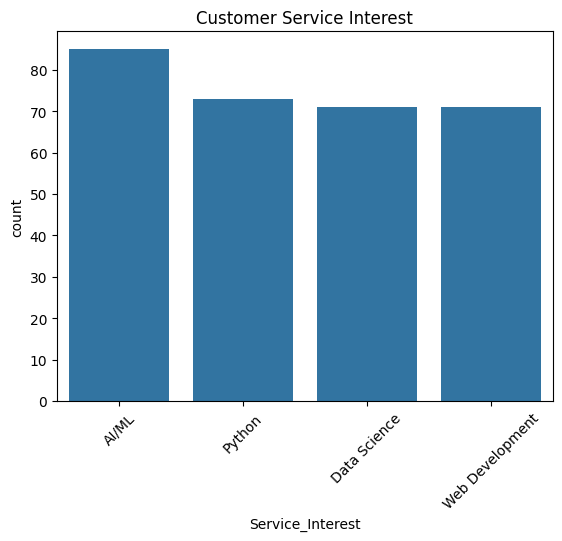

In [6]:

sns.countplot(data=df, x="Service_Interest")

plt.title("Customer Service Interest")
plt.xticks(rotation=45)
plt.show()


In [7]:

features = [
    "Spending",
    "Visits",
    "Engagement",
    "Service_Usage"
]

X = df[features]

X.head()


,Spending,Visits,Engagement,Service_Usage
0,8392,17,88,6
1,14949,4,79,14
2,19091,12,30,9
3,6791,29,51,2
4,5931,9,81,5


In [8]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])


[[-0.35452135  0.2182247   1.3831622  -0.38185896]
 [ 0.85833481 -1.30700169  1.07475209  1.58479663]
 [ 1.62448552 -0.36840084 -0.60436958  0.35563689]
 [-0.65066024  1.62612598  0.115254   -1.36518676]
 [-0.80973548 -0.72037616  1.14328767 -0.62769091]]


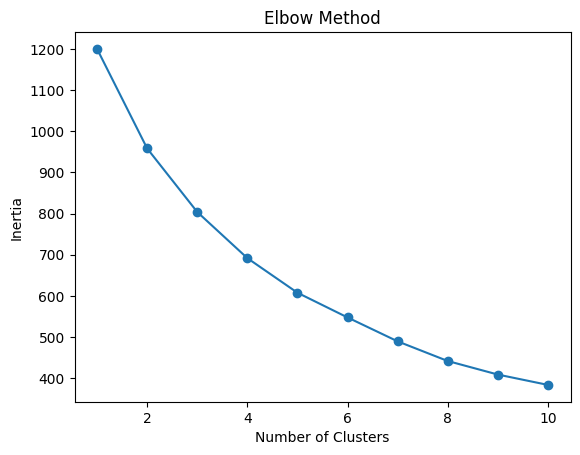

In [9]:

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)

    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()


In [10]:

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

df.head()


,Customer_ID,Age,Spending,Visits,Engagement,Service_Interest,Service_Usage,Cluster
0,1,24,8392,17,88,AI/ML,6,3
1,2,37,14949,4,79,Python,14,2
2,3,46,19091,12,30,Data Science,9,2
3,4,32,6791,29,51,Web Development,2,3
4,5,28,5931,9,81,Data Science,5,3


In [11]:

score = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", score)


Silhouette Score: 0.205356744816952


In [12]:

segment_profiles = df.groupby("Cluster")[features].mean()

print(segment_profiles)


             Spending     Visits  Engagement  Service_Usage
Cluster                                                    
0        12305.452055  20.082192   17.808219       6.369863
1         6192.130952   9.738095   38.404762      10.440476
2        15935.215385   8.630769   60.753846       6.861538
3         8184.141026  21.756410   74.564103       6.128205


In [13]:

segment_names = {
    0: "Low Engagement Customers",
    1: "Highly Engaged Customers",
    2: "Moderate Customers",
    3: "High Spending Customers"
}

df["Segment"] = df["Cluster"].map(segment_names)

df[["Customer_ID", "Cluster", "Segment"]].head()


,Customer_ID,Cluster,Segment
0,1,3,High Spending Customers
1,2,2,Moderate Customers
2,3,2,Moderate Customers
3,4,3,High Spending Customers
4,5,3,High Spending Customers


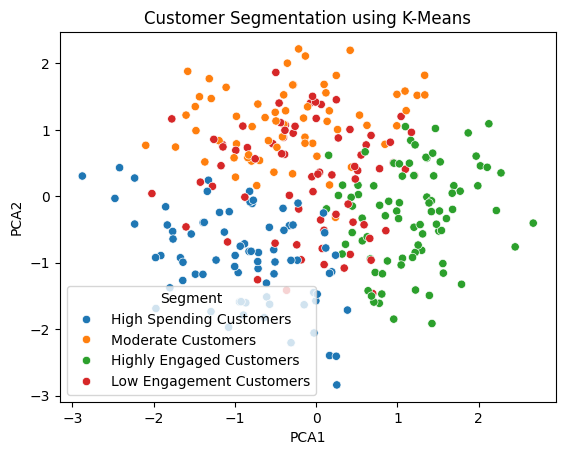

In [14]:

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

df["PCA1"] = X_pca[:, 0]
df["PCA2"] = X_pca[:, 1]

sns.scatterplot(
    data=df,
    x="PCA1",
    y="PCA2",
    hue="Segment",
    palette="tab10"
)

plt.title("Customer Segmentation using K-Means")
plt.show()


In [15]:

def recommend_service(row):

    if row["Segment"] == "Highly Engaged Customers":
        return "Advanced AI/ML Program"

    elif row["Segment"] == "Low Engagement Customers":
        return "Beginner Python Course"

    elif row["Segment"] == "High Spending Customers":
        return "Premium Data Science Program"

    else:
        return "Introductory Workshop"


df["Recommended_Service"] = df.apply(
    recommend_service,
    axis=1
)

df[[
    "Customer_ID",
    "Segment",
    "Recommended_Service"
]].head(10)


,Customer_ID,Segment,Recommended_Service
0,1,High Spending Customers,Premium Data Science Program
1,2,Moderate Customers,Introductory Workshop
2,3,Moderate Customers,Introductory Workshop
3,4,High Spending Customers,Premium Data Science Program
4,5,High Spending Customers,Premium Data Science Program
5,6,Highly Engaged Customers,Advanced AI/ML Program
6,7,Low Engagement Customers,Beginner Python Course
7,8,Low Engagement Customers,Beginner Python Course
8,9,Highly Engaged Customers,Advanced AI/ML Program
9,10,High Spending Customers,Premium Data Science Program


In [16]:

final_report = df[[
    "Customer_ID",
    "Age",
    "Spending",
    "Visits",
    "Engagement",
    "Service_Interest",
    "Segment",
    "Recommended_Service"
]]

final_report.head(10)


,Customer_ID,Age,Spending,Visits,Engagement,Service_Interest,Segment,Recommended_Service
0,1,24,8392,17,88,AI/ML,High Spending Customers,Premium Data Science Program
1,2,37,14949,4,79,Python,Moderate Customers,Introductory Workshop
2,3,46,19091,12,30,Data Science,Moderate Customers,Introductory Workshop
3,4,32,6791,29,51,Web Development,High Spending Customers,Premium Data Science Program
4,5,28,5931,9,81,Data Science,High Spending Customers,Premium Data Science Program
5,6,25,1202,19,5,Data Science,Highly Engaged Customers,Advanced AI/ML Program
6,7,46,12447,12,29,Data Science,Low Engagement Customers,Beginner Python Course
7,8,38,13688,9,4,Python,Low Engagement Customers,Beginner Python Course
8,9,24,5389,7,10,AI/ML,Highly Engaged Customers,Advanced AI/ML Program
9,10,43,3327,28,56,Data Science,High Spending Customers,Premium Data Science Program


In [19]:

df.to_csv("customer_segmentation_results.csv", index=False)

print("CSV file created successfully!")




CSV file created successfully!


In [20]:

import os

print(os.listdir())


['.config', 'customer_segmentation_results.csv', 'sample_data']


In [21]:

from google.colab import files

files.download("customer_segmentation_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>